In [1]:
pip install scikit-learn matplotlib numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import fetch_openml

In [3]:
X, y = fetch_openml("mnist_784", version = 1, return_X_y = True, as_frame = False, parser = "auto")
# mnist_784 ((28*28) 784 is the number of features per image) & version = 1 is the first version of the dataset
# return_X_y = True returns it as a 2-element tuple
# as_frame = False, unpacks it as a NumPy array
# parser = "auto" selects the best possible parser

In [4]:
X = X / 255.0 
# Normalizing [0, 255] to [0.0, 1.0]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 10000, stratify = y, random_state = 42)
y_train = y_train.astype(int) # Converting str to int
y_test = y_test.astype(int)

In [6]:
model = MLPClassifier(hidden_layer_sizes = (128, 64), activation = "relu", solver = "adam", alpha = 0.001, early_stopping = True, validation_fraction = 0.1, n_iter_no_change = 5, max_iter = 100, batch_size = 256, verbose = True, random_state = 42)
model.fit(X_train, y_train)

Iteration 1, loss = 0.44051232
Validation score: 0.939667
Iteration 2, loss = 0.17000559
Validation score: 0.958167
Iteration 3, loss = 0.12183894
Validation score: 0.964333
Iteration 4, loss = 0.09405571
Validation score: 0.966833
Iteration 5, loss = 0.07492239
Validation score: 0.969333
Iteration 6, loss = 0.06105920
Validation score: 0.972833
Iteration 7, loss = 0.05067962
Validation score: 0.972667
Iteration 8, loss = 0.04153408
Validation score: 0.974167
Iteration 9, loss = 0.03445932
Validation score: 0.972500
Iteration 10, loss = 0.02920972
Validation score: 0.976167
Iteration 11, loss = 0.02543471
Validation score: 0.976667
Iteration 12, loss = 0.02119874
Validation score: 0.974833
Iteration 13, loss = 0.01691608
Validation score: 0.977833
Iteration 14, loss = 0.01380967
Validation score: 0.975167
Iteration 15, loss = 0.01232935
Validation score: 0.977000
Iteration 16, loss = 0.01153484
Validation score: 0.974667
Iteration 17, loss = 0.00962474
Validation score: 0.975833
Iterat

,hidden_layer_sizes,"(128, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.001
,batch_size,256
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,100
,shuffle,True
,random_state,42


In [12]:
training_accuracy = model.score(X_train, y_train)
testing_accuracy = model.score(X_test, y_test)
print(f"Training Accuracy: {training_accuracy * 100 : .2f}%")
print(f"Testing Accuracy: {testing_accuracy * 100 : .2f}%")

Training Accuracy:  99.55%
Testing Accuracy:  97.84%


In [8]:
y_pred = model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       986
           1       0.98      0.99      0.99      1125
           2       0.99      0.97      0.98       999
           3       0.99      0.98      0.98      1020
           4       0.95      0.98      0.97       975
           5       0.97      0.98      0.98       902
           6       0.99      0.99      0.99       982
           7       0.98      0.98      0.98      1042
           8       0.98      0.97      0.97       975
           9       0.97      0.95      0.96       994

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



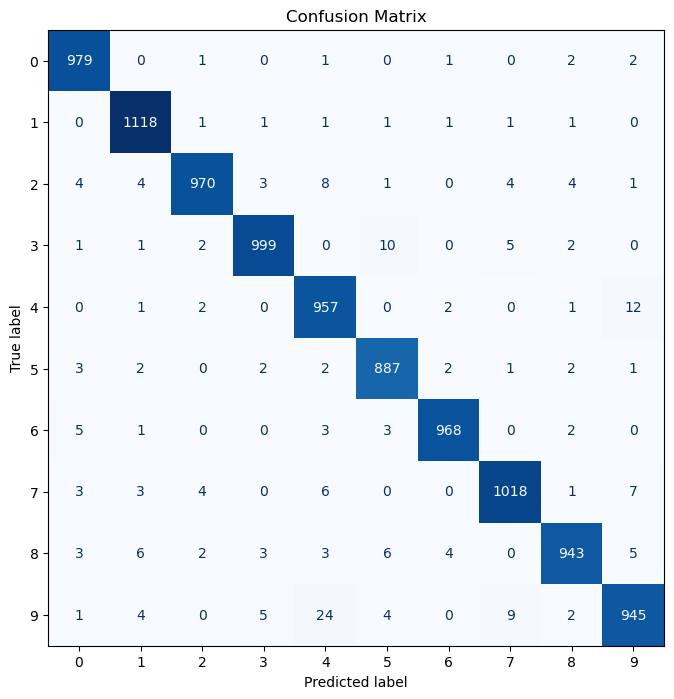

In [9]:
fig1, axes1 = plt.subplots(figsize = (8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax = axes1, cmap = "Blues", colorbar = False)
plt.title("Confusion Matrix")
plt.show()

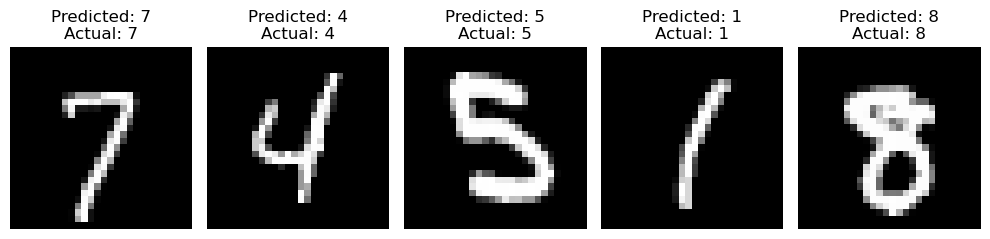

In [10]:
# Correct Actual and Predicted
fig3, axes3 = plt.subplots(1, 5, figsize = (10, 3))
for i, a in enumerate(axes3):
    a.imshow(X_test[i].reshape(28, 28), cmap = "gray")
    a.set_title(f"Predicted: {y_pred[i]}\nActual: {y_test[i]}")
    a.axis("off")
plt.tight_layout()
plt.show()

Total misclassified 216 out of 10000


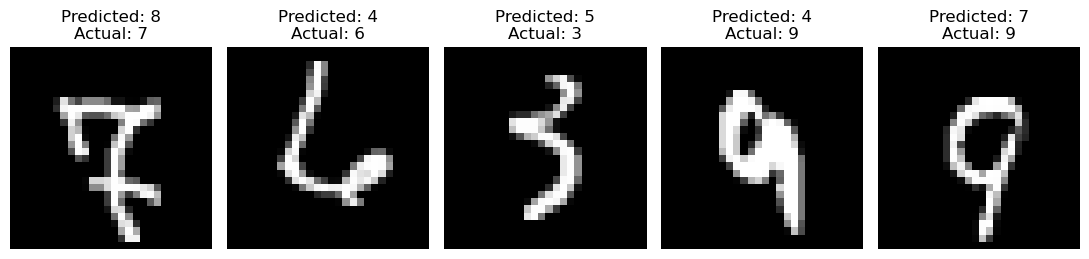

In [11]:
# Incorrect Actual and Predicted
misclassified = np.where(y_pred != y_test)[0]
print(f"Total misclassified {len(misclassified)} out of {len(y_test)}")
fig2, axes2 = plt.subplots(1, 5, figsize = (11, 3))
for i, j in enumerate(misclassified[:5]):
    axes2[i].imshow(X_test[j].reshape(28, 28), cmap = "gray")
    axes2[i].set_title(f"Predicted: {y_pred[j]}\nActual: {y_test[j]}")
    axes2[i].axis("off")
plt.tight_layout()
plt.show()